1 Data understanding

1.1 Data reading and printing the first 5 rows

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = pd.read_csv("data/merged_laliga_all.csv")
df= data.copy()
df.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,...,AST,HF,AF,HC,AC,HY,AY,HR,AR,Referee
0,11/8/2023,Almeria,Vallecano,0,2,A,0,2,A,19,...,4,16,25,8,3,1,3,0,0,NaN
1,11/8/2023,Sevilla,Valencia,1,2,A,0,0,D,9,...,3,15,17,8,1,3,2,1,0,NaN
2,12/8/2023,Sociedad,Girona,1,1,D,1,0,H,15,...,1,22,9,4,1,2,5,0,0,NaN
3,12/8/2023,Las Palmas,Mallorca,1,1,D,1,0,H,5,...,2,11,21,3,6,3,2,0,0,NaN
4,12/8/2023,Ath Bilbao,Real Madrid,0,2,A,0,2,A,7,...,8,18,6,7,5,3,1,0,0,NaN


1.2Random sample from the data

In [4]:
df.sample(5)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,...,AST,HF,AF,HC,AC,HY,AY,HR,AR,Referee
484,28/10/21,Granada,Getafe,1,1,D,0,1,A,18,...,4,10,15,5,0,1,4,0,0,NaN
613,13/02/22,Levante,Betis,2,4,A,1,3,A,12,...,11,13,8,5,7,1,2,1,0,NaN
3262,8/2/2025,Ath Bilbao,Girona,3,0,H,2,0,H,23,...,1,7,12,11,2,0,4,0,0,NaN
2488,25/01/16,Levante,Las Palmas,3,2,H,1,0,H,12,...,4,22,11,2,4,2,4,1,0,NaN
2154,2/3/2019,Villarreal,Alaves,1,2,A,0,0,D,9,...,2,15,12,8,2,2,3,0,0,NaN


1.3 Size of data using shape function

In [5]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3420 entries, 0 to 3419
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      3420 non-null   object 
 1   HomeTeam  3420 non-null   object 
 2   AwayTeam  3420 non-null   object 
 3   FTHG      3420 non-null   int64  
 4   FTAG      3420 non-null   int64  
 5   FTR       3420 non-null   object 
 6   HTHG      3420 non-null   int64  
 7   HTAG      3420 non-null   int64  
 8   HTR       3420 non-null   object 
 9   HS        3420 non-null   int64  
 10  AS        3420 non-null   int64  
 11  HST       3420 non-null   int64  
 12  AST       3420 non-null   int64  
 13  HF        3420 non-null   int64  
 14  AF        3420 non-null   int64  
 15  HC        3420 non-null   int64  
 16  AC        3420 non-null   int64  
 17  HY        3420 non-null   int64  
 18  AY        3420 non-null   int64  
 19  HR        3420 non-null   int64  
 20  AR        3420 non-null   int6

(3420, 22)

In [6]:
df = df.drop(['Date','Referee'] , axis=1)


encoding of the home,away teams , the HTR and FTR

In [7]:
from sklearn.preprocessing import LabelEncoder

le_team=LabelEncoder()


le_team.fit(pd.concat([df['HomeTeam'],df['AwayTeam']]))   # to make the numerical number constant whether its home or away example: real madrid = 1 if its home or away
df['HomeTeam']=le_team.transform(df['HomeTeam'])
df['AwayTeam']=le_team.transform(df['AwayTeam'])

htr_map = {'H': 0, 'D': 1, 'A': 2}
df['HTR'] = df['HTR'].map(htr_map)


ftr_map = {'H': 0, 'D': 1, 'A': 2}
df['FTR'] = df['FTR'].map(ftr_map)

In [8]:
# Mapping from encoded numbers back to original team names
team_map = dict(zip(le_team.transform(le_team.classes_), le_team.classes_))
print(team_map)


{np.int64(0): 'Alaves', np.int64(1): 'Almeria', np.int64(2): 'Ath Bilbao', np.int64(3): 'Ath Madrid', np.int64(4): 'Barcelona', np.int64(5): 'Betis', np.int64(6): 'Cadiz', np.int64(7): 'Celta', np.int64(8): 'Eibar', np.int64(9): 'Elche', np.int64(10): 'Espanol', np.int64(11): 'Getafe', np.int64(12): 'Girona', np.int64(13): 'Granada', np.int64(14): 'Huesca', np.int64(15): 'La Coruna', np.int64(16): 'Las Palmas', np.int64(17): 'Leganes', np.int64(18): 'Levante', np.int64(19): 'Malaga', np.int64(20): 'Mallorca', np.int64(21): 'Osasuna', np.int64(22): 'Real Madrid', np.int64(23): 'Sevilla', np.int64(24): 'Sociedad', np.int64(25): 'Sp Gijon', np.int64(26): 'Valencia', np.int64(27): 'Valladolid', np.int64(28): 'Vallecano', np.int64(29): 'Villarreal'}


1.4 Info of data

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3420 entries, 0 to 3419
Data columns (total 20 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   HomeTeam  3420 non-null   int64
 1   AwayTeam  3420 non-null   int64
 2   FTHG      3420 non-null   int64
 3   FTAG      3420 non-null   int64
 4   FTR       3420 non-null   int64
 5   HTHG      3420 non-null   int64
 6   HTAG      3420 non-null   int64
 7   HTR       3420 non-null   int64
 8   HS        3420 non-null   int64
 9   AS        3420 non-null   int64
 10  HST       3420 non-null   int64
 11  AST       3420 non-null   int64
 12  HF        3420 non-null   int64
 13  AF        3420 non-null   int64
 14  HC        3420 non-null   int64
 15  AC        3420 non-null   int64
 16  HY        3420 non-null   int64
 17  AY        3420 non-null   int64
 18  HR        3420 non-null   int64
 19  AR        3420 non-null   int64
dtypes: int64(20)
memory usage: 534.5 KB


1.5 Check names of columns

In [10]:
df.columns.tolist()

['HomeTeam',
 'AwayTeam',
 'FTHG',
 'FTAG',
 'FTR',
 'HTHG',
 'HTAG',
 'HTR',
 'HS',
 'AS',
 'HST',
 'AST',
 'HF',
 'AF',
 'HC',
 'AC',
 'HY',
 'AY',
 'HR',
 'AR']

1.6 check Description

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HomeTeam,3420.0,14.438889,9.158706,0.0,5.75,13.5,23.0,29.0
AwayTeam,3420.0,14.438889,9.158706,0.0,5.75,13.5,23.0,29.0
FTHG,3420.0,1.503509,1.294685,0.0,1.00,1.0,2.0,10.0
FTAG,3420.0,1.132749,1.117770,0.0,0.00,1.0,2.0,8.0
FTR,3420.0,0.823977,0.842709,0.0,0.00,1.0,2.0,2.0
HTHG,3420.0,0.661404,0.839906,0.0,0.00,0.0,1.0,5.0
HTAG,3420.0,0.486550,0.709354,0.0,0.00,0.0,1.0,5.0
HTR,3420.0,0.889181,0.743304,0.0,0.00,1.0,1.0,2.0
HS,3420.0,13.402924,4.952857,2.0,10.00,13.0,16.0,40.0
AS,3420.0,10.481579,4.312922,0.0,7.00,10.0,13.0,35.0


1.7 check number of unique

In [12]:
df.nunique()

,0
HomeTeam,30
AwayTeam,30
FTHG,10
FTAG,9
FTR,3
HTHG,6
HTAG,6
HTR,3
HS,37
AS,31


1.8 check the balance

In [13]:
print("Home matches per team:")
print(df['HomeTeam'].value_counts().head())

print("\nAway matches per team:")
print(df['AwayTeam'].value_counts().head())



Home matches per team:
HomeTeam
23    171
24    171
7     171
2     171
3     171
Name: count, dtype: int64

Away matches per team:
AwayTeam
26    171
22    171
29    171
7     171
4     171
Name: count, dtype: int64


2.0 Data cleaning

2.1 Checking the missing values

In [14]:
print("missing values per column:\n", df.isnull().sum())

missing values per column:
 HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64


2.2 Detect and deop duplicates if found

In [15]:

duplicates = df.duplicated().sum()
print(f" Number of duplicate rows: {duplicates}")


df_clean = df.drop_duplicates()
print(f" Dataset shape after removing duplicates: {df_clean.shape}")


 Number of duplicate rows: 0
 Dataset shape after removing duplicates: (3420, 20)


2.3 Outlier detection

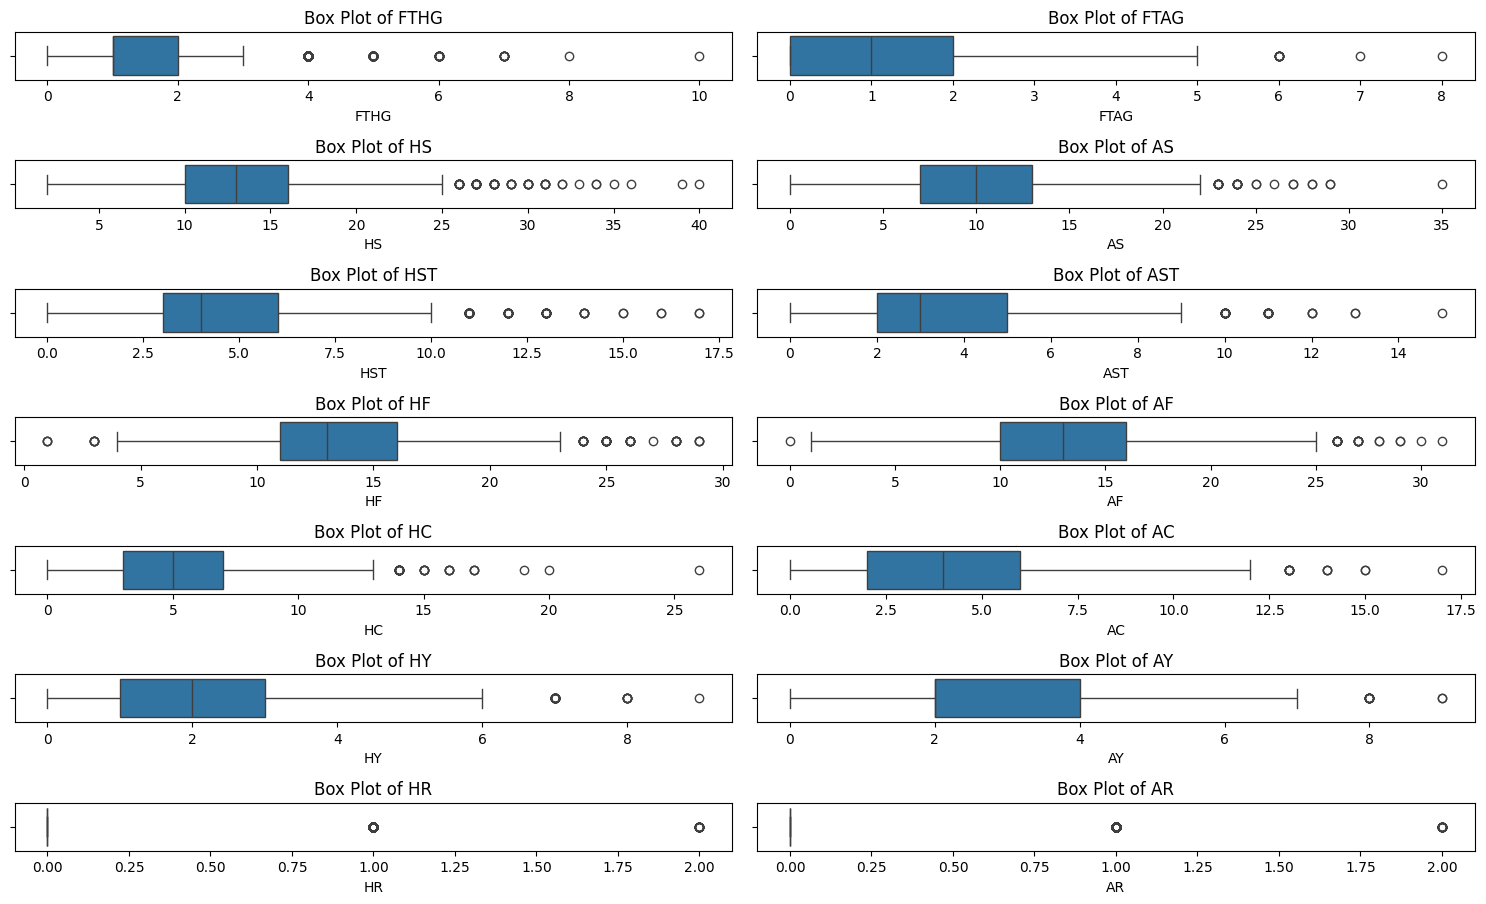

In [16]:
num_cols = [
    'FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST',
    'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR'
]
plt.figure(figsize=(15,10))
for i , feature in enumerate(num_cols):
  plt.subplot(8,2,i+1)
  sns.boxplot(x=df[feature])
  plt.title(f'Box Plot of {feature}')
plt.tight_layout()
plt.show()

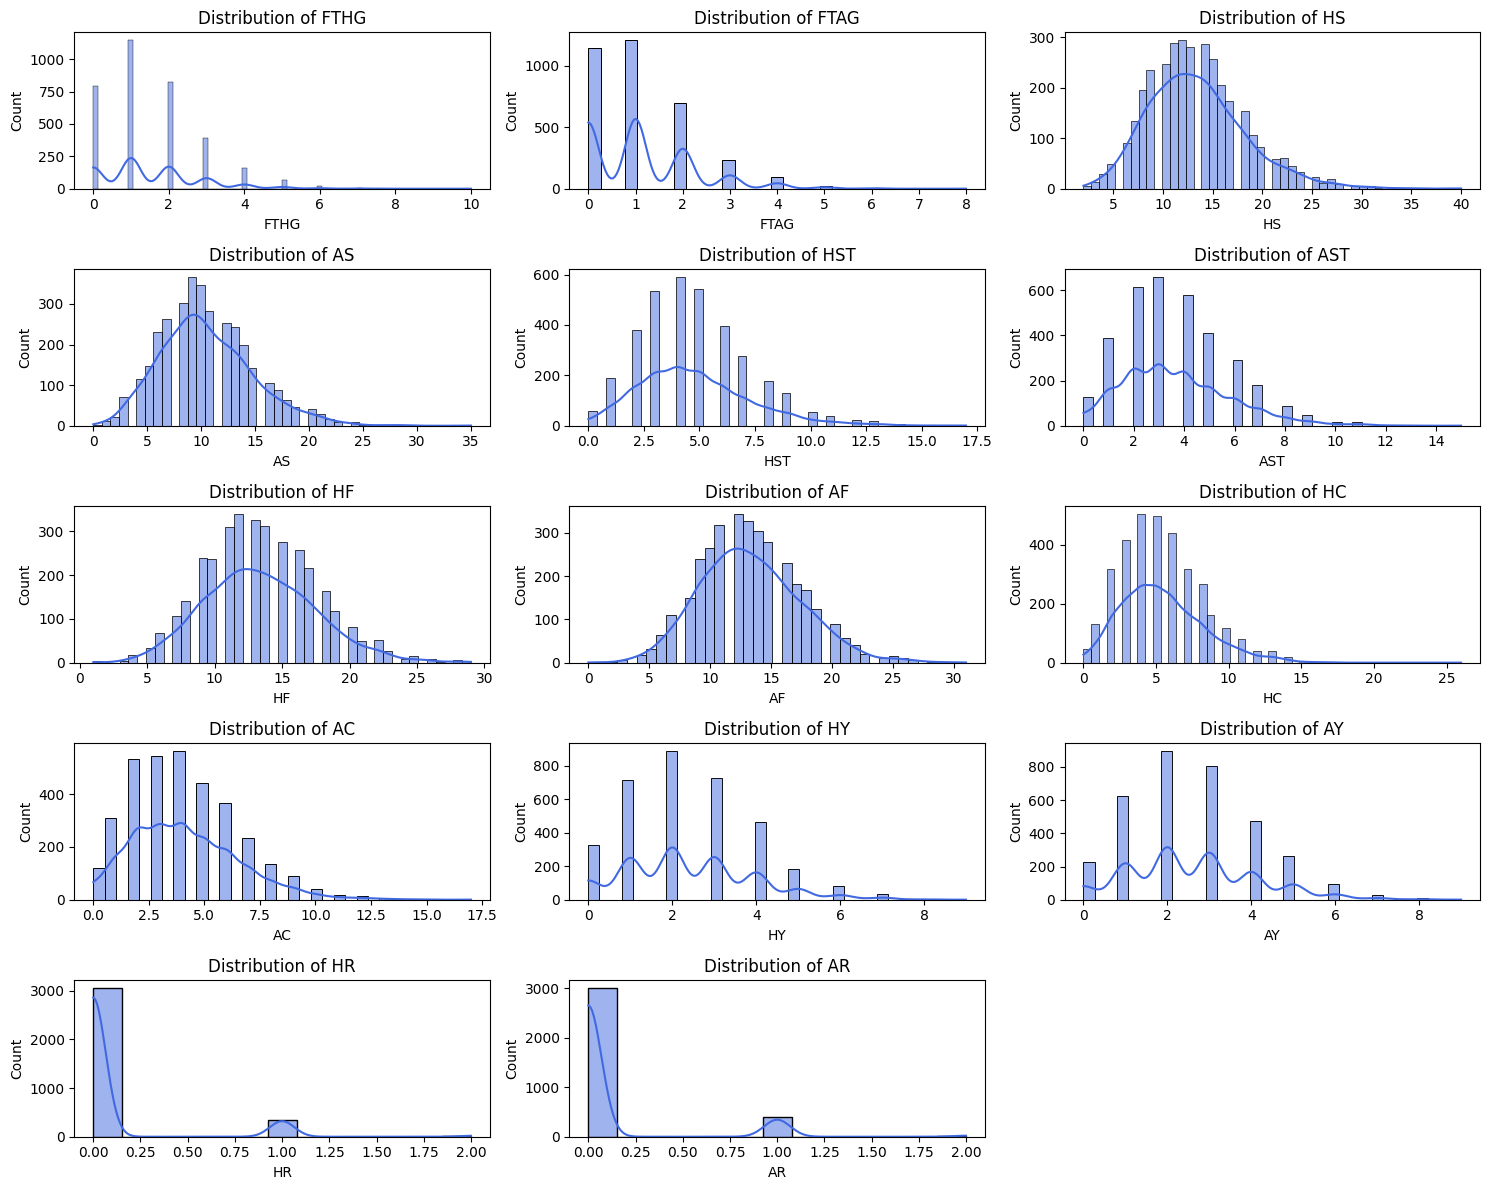

In [17]:

plt.figure(figsize=(15, 12))
for i, col in enumerate(num_cols):
    plt.subplot(len(num_cols)//3 + 1, 3, i+1)
    sns.histplot(df[col], kde=True, color='royalblue')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()


end of phase 1

EDA

Univariate Analysis

Boxplots for numerical features

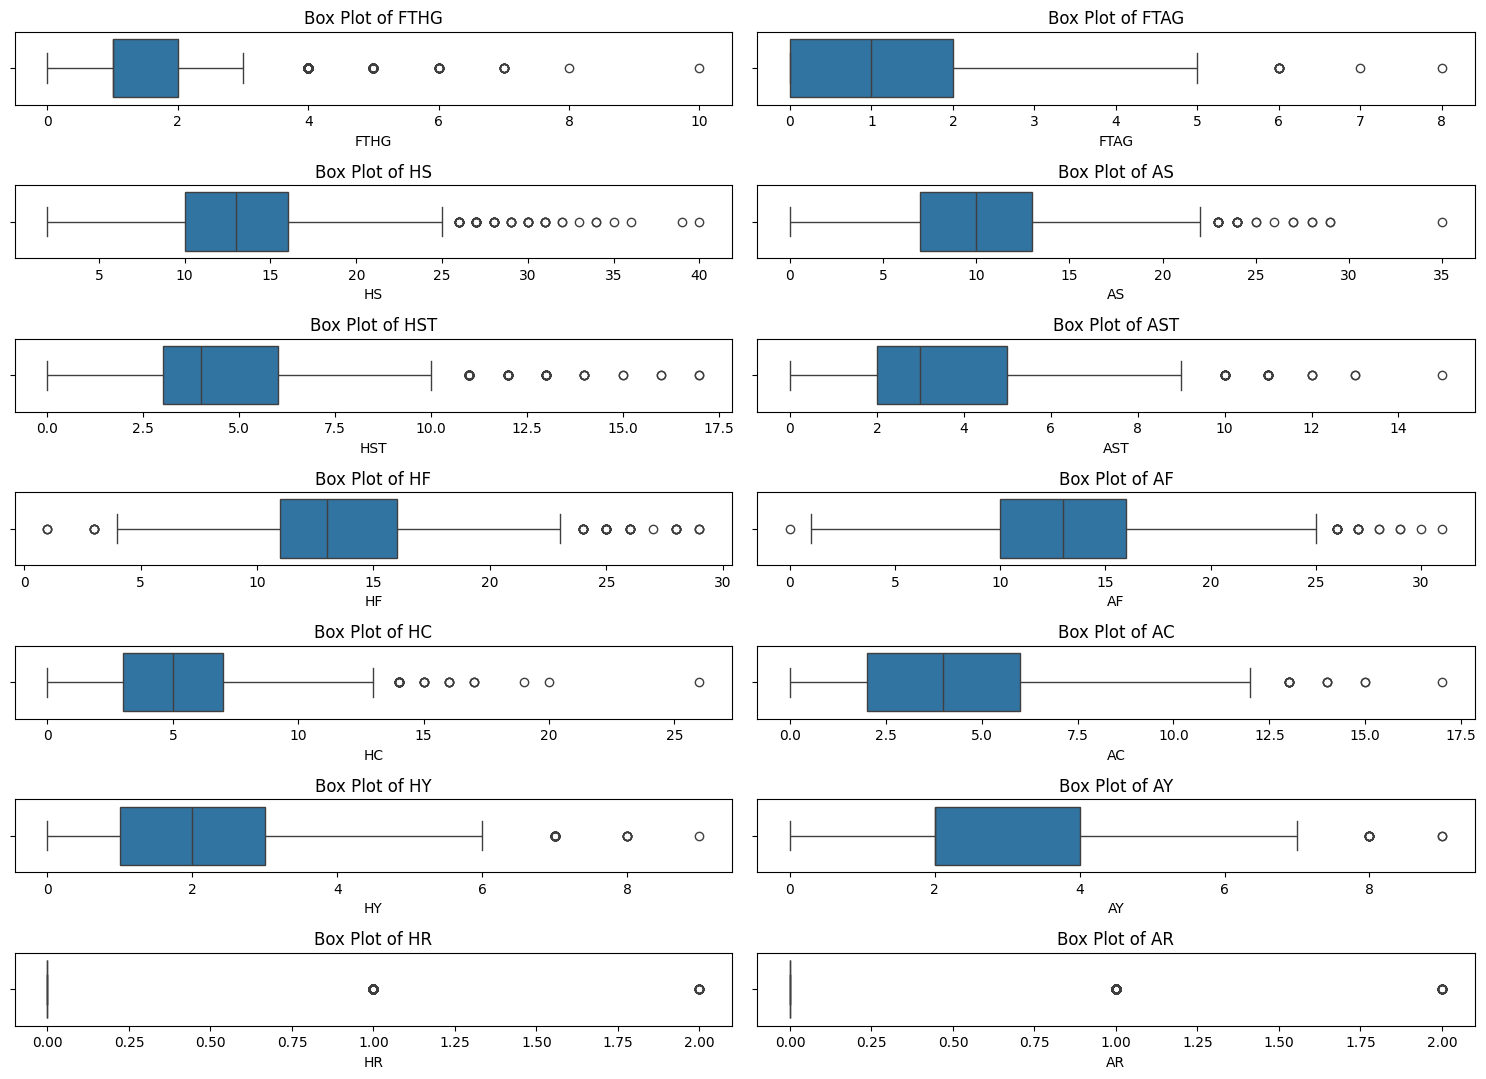

In [18]:
plt.figure(figsize=(15, 12))
for i, feature in enumerate(num_cols):
  plt.subplot(8,2,i+1)
  sns.boxplot(x=df[feature])
  plt.title(f'Box Plot of {feature}')
plt.tight_layout()
plt.show()

check skewness and kurtosis

In [19]:
summary_stats=df[num_cols].describe().T
summary_stats["skewness"] = df[num_cols].skew()
summary_stats["kurtosis"] = df[num_cols].kurt()
summary_stats


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
FTHG,3420.0,1.503509,1.294685,0.0,1.0,1.0,2.0,10.0,1.063547,1.652971
FTAG,3420.0,1.132749,1.117770,0.0,0.0,1.0,2.0,8.0,1.150204,1.737187
HS,3420.0,13.402924,4.952857,2.0,10.0,13.0,16.0,40.0,0.727411,1.092471
AS,3420.0,10.481579,4.312922,0.0,7.0,10.0,13.0,35.0,0.608885,0.668508
HST,3420.0,4.728070,2.517741,0.0,3.0,4.0,6.0,17.0,0.782602,0.992972
AST,3420.0,3.657602,2.158535,0.0,2.0,3.0,5.0,15.0,0.732582,0.669578
HF,3420.0,13.384211,4.142785,1.0,11.0,13.0,16.0,29.0,0.338809,0.192867
AF,3420.0,13.307602,4.168237,0.0,10.0,13.0,16.0,31.0,0.396711,0.268016
HC,3420.0,5.438304,2.886565,0.0,3.0,5.0,7.0,26.0,0.817575,1.340861
AC,3420.0,4.126608,2.429237,0.0,2.0,4.0,6.0,17.0,0.725106,0.739797


CountPlots for categorical features

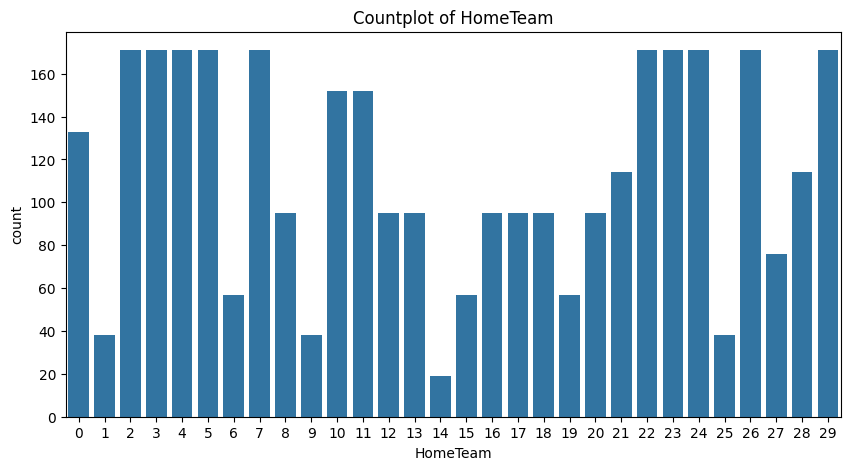

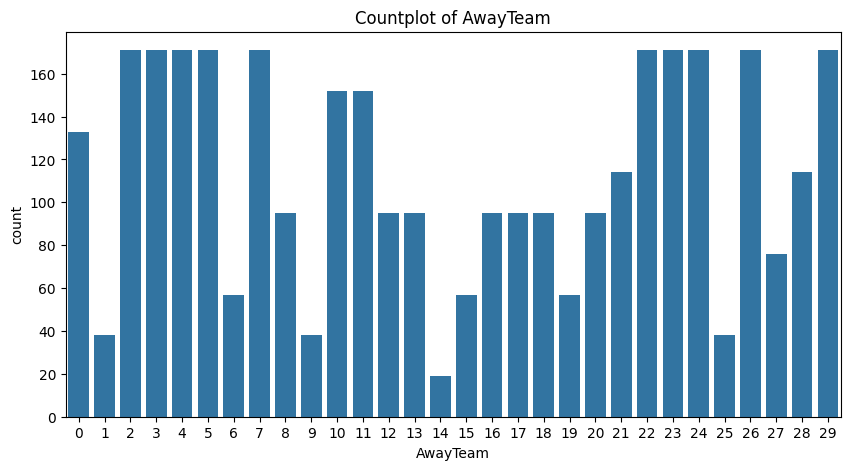

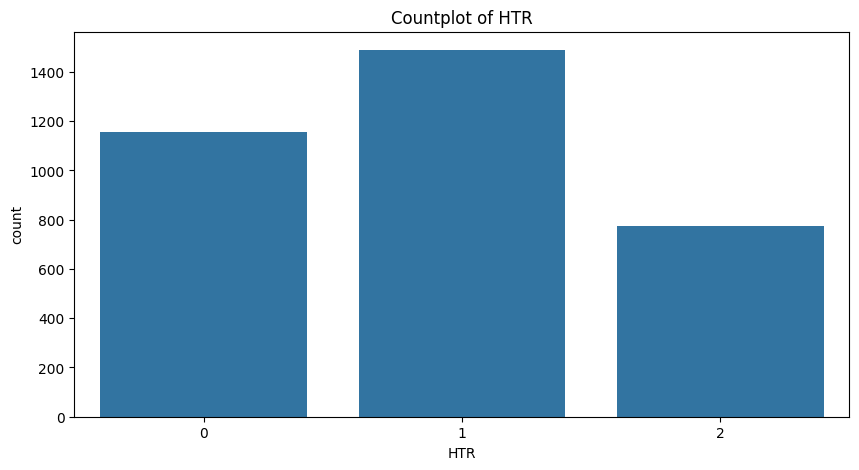

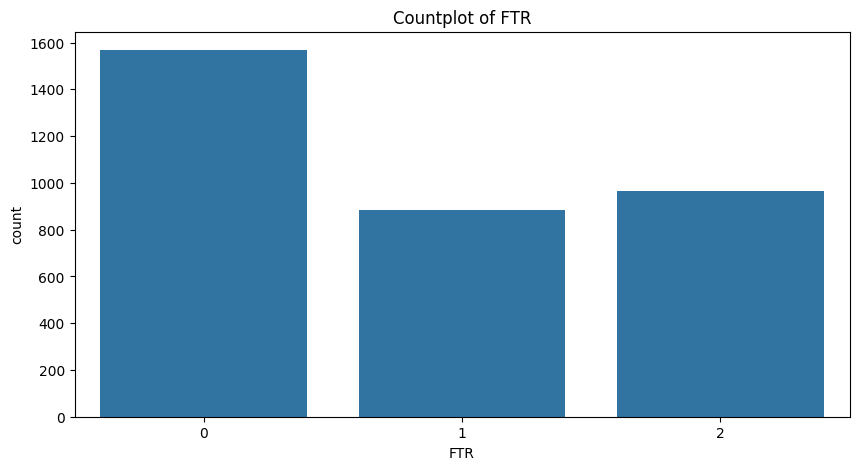

In [20]:


cat_cols = ['HomeTeam','AwayTeam','HTR','FTR']

for feature in cat_cols:
    plt.figure(figsize=(10,5))
    sns.countplot(x=df[feature])
    plt.title(f'Countplot of {feature}')
    plt.show()


check skewness

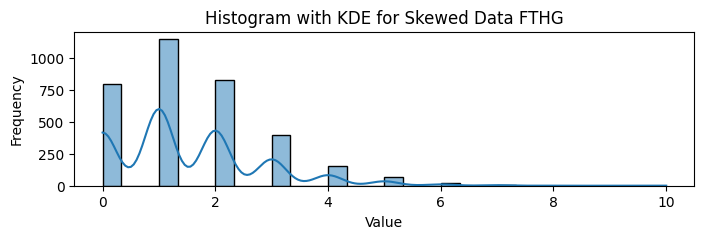

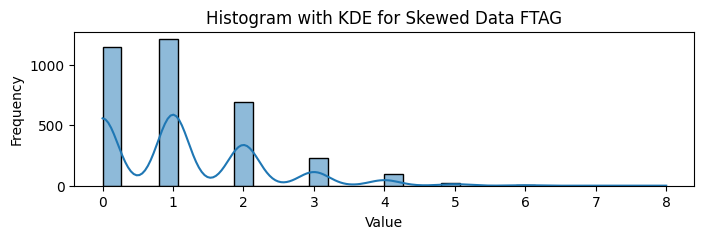

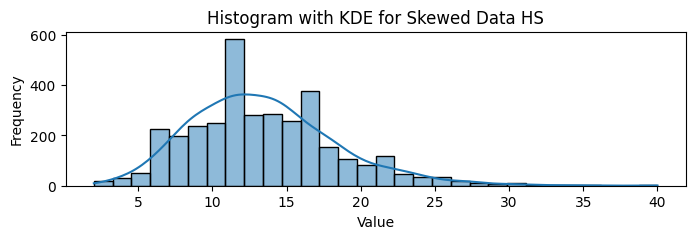

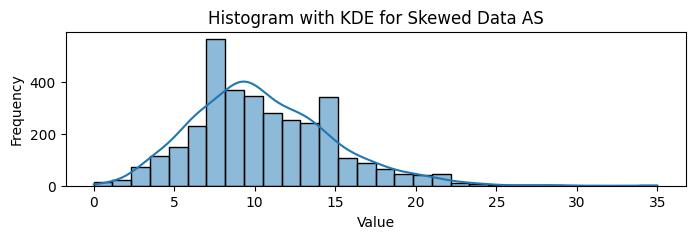

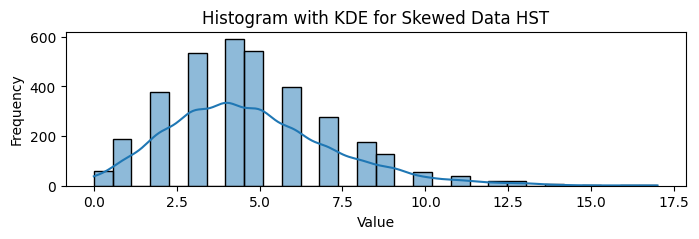

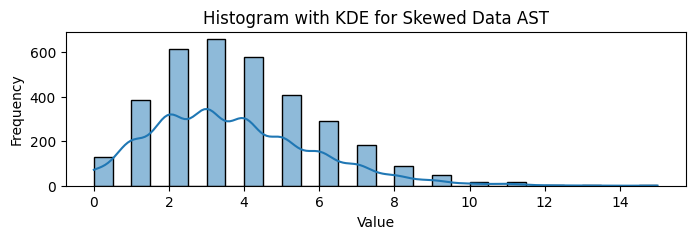

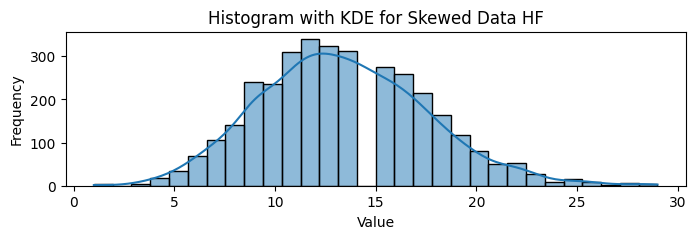

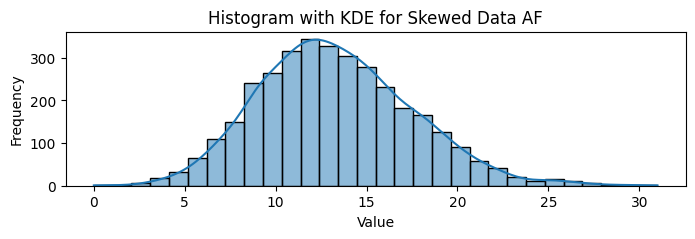

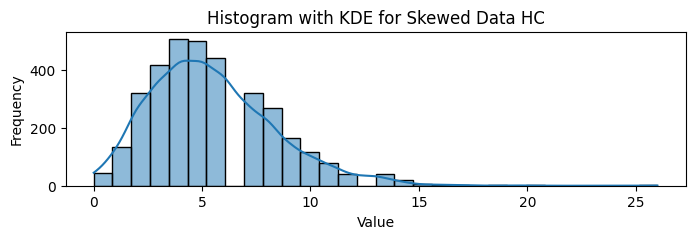

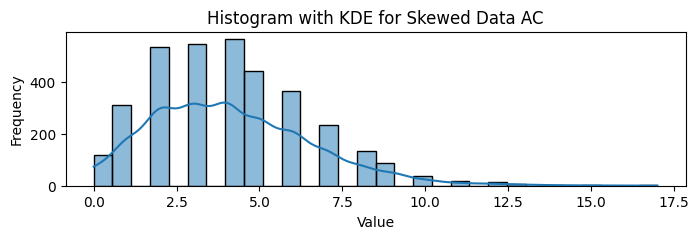

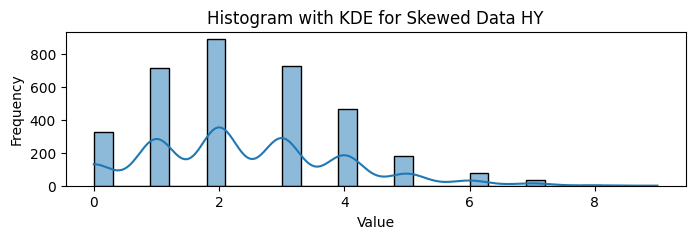

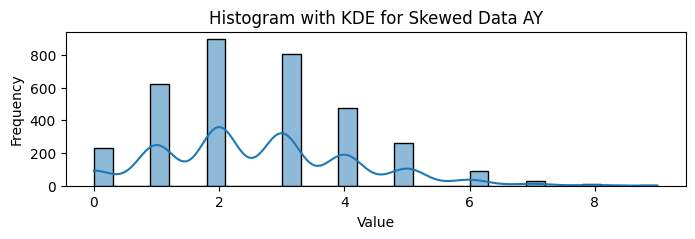

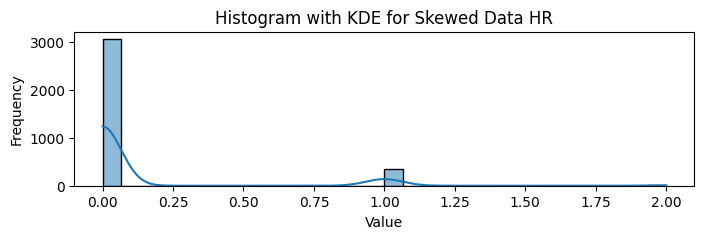

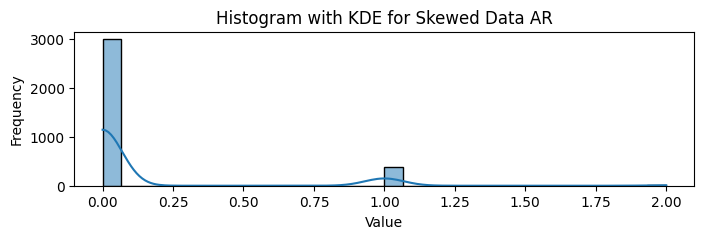

In [21]:
for feature in num_cols:
  plt.figure(figsize=(8, 2))
  sns.histplot(df[feature], kde=True, bins=30)
  plt.title(f'Histogram with KDE for Skewed Data {feature}')
  plt.xlabel('Value')
  plt.ylabel('Frequency')
  plt.show()

# **Bivariate Analysis**

1. correlation matrix

In [22]:
corr = df[num_cols].corr()
print(corr)


          FTHG      FTAG        HS        AS       HST       AST        HF  \
FTHG  1.000000 -0.028213  0.246587 -0.031076  0.574370 -0.050905 -0.105278   
FTAG -0.028213  1.000000  0.018601  0.279409 -0.018972  0.588962 -0.025355   
HS    0.246587  0.018601  1.000000 -0.251658  0.646200 -0.126427 -0.200168   
AS   -0.031076  0.279409 -0.251658  1.000000 -0.131312  0.639939 -0.005726   
HST   0.574370 -0.018972  0.646200 -0.131312  1.000000 -0.083818 -0.153377   
AST  -0.050905  0.588962 -0.126427  0.639939 -0.083818  1.000000 -0.005694   
HF   -0.105278 -0.025355 -0.200168 -0.005726 -0.153377 -0.005694  1.000000   
AF   -0.051688 -0.050199 -0.055577 -0.147771 -0.060197 -0.126189  0.014953   
HC   -0.017356  0.025020  0.503800 -0.252153  0.277915 -0.125417 -0.134837   
AC   -0.012463 -0.007161 -0.267464  0.475709 -0.144480  0.242486 -0.011374   
HY   -0.130426  0.060802 -0.153521  0.052736 -0.149621  0.050066  0.366205   
AY   -0.000834 -0.039217  0.012579 -0.112045  0.007161 -0.094154

2.Heatmap of correlations

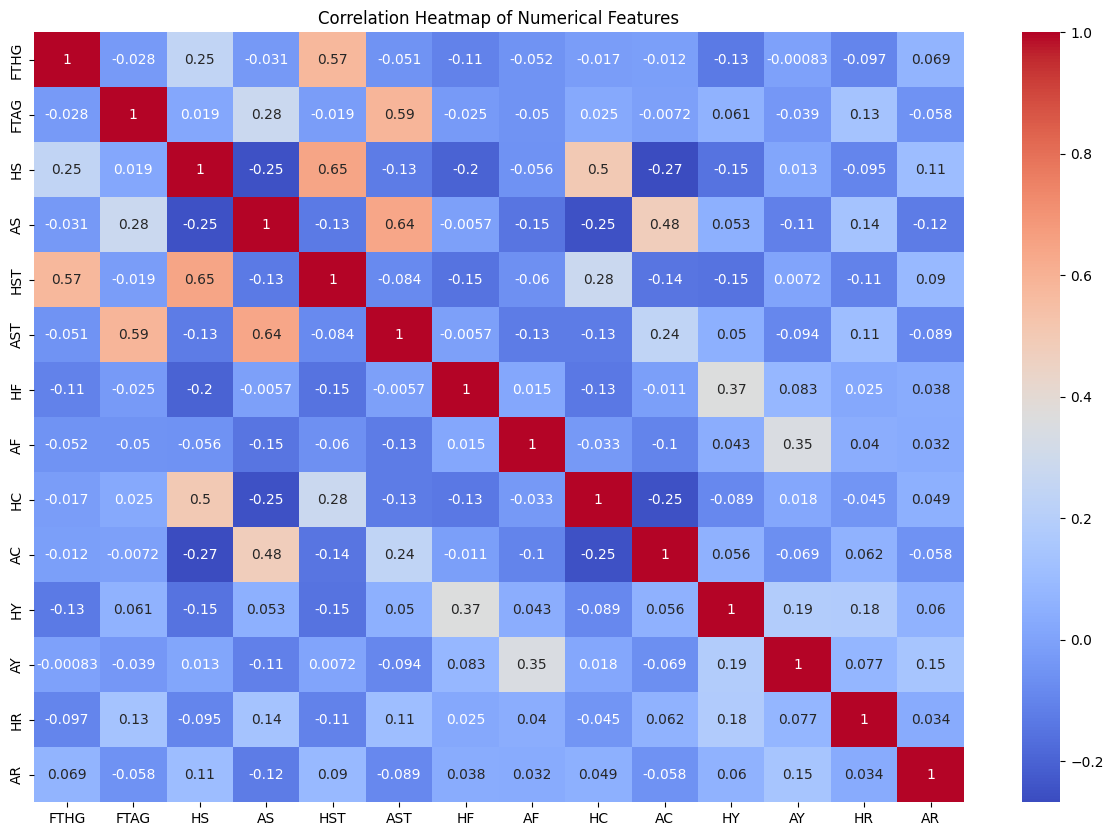

In [23]:
plt.figure(figsize=(15,10))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

3. scatter plots

home scattrer plots

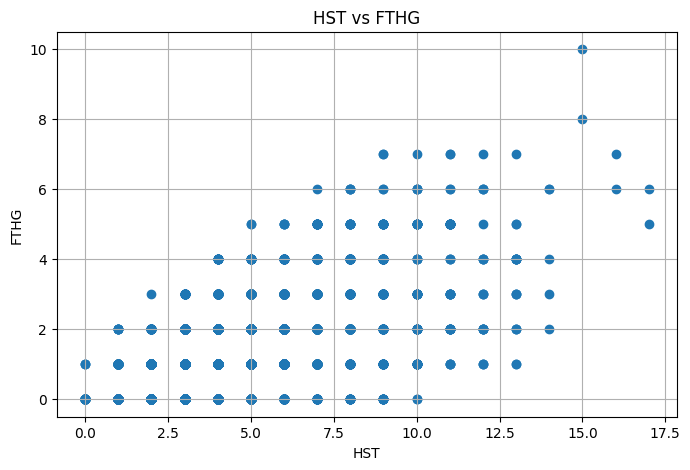

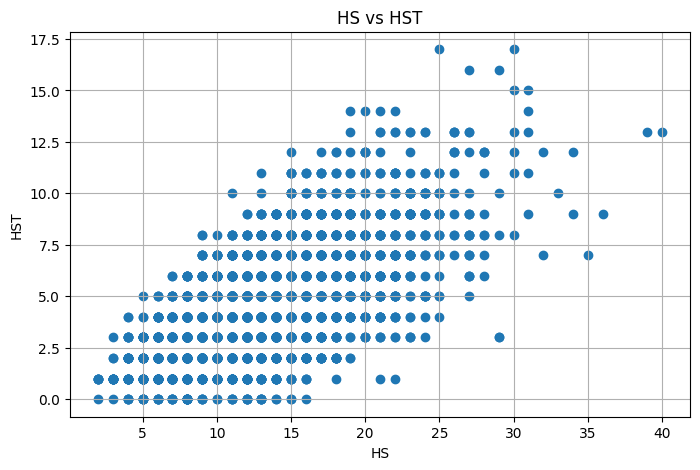

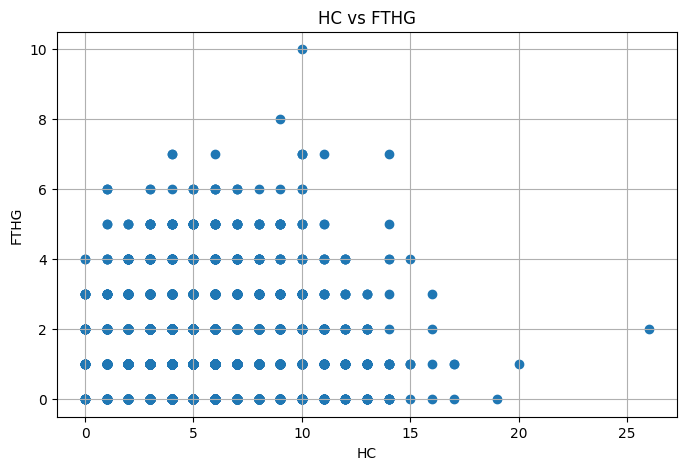

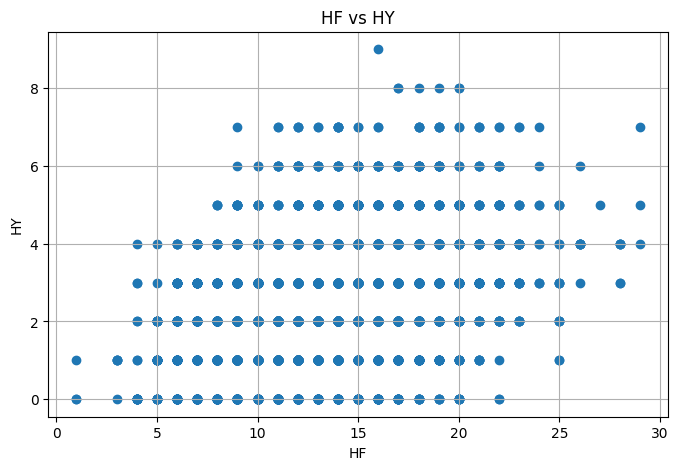

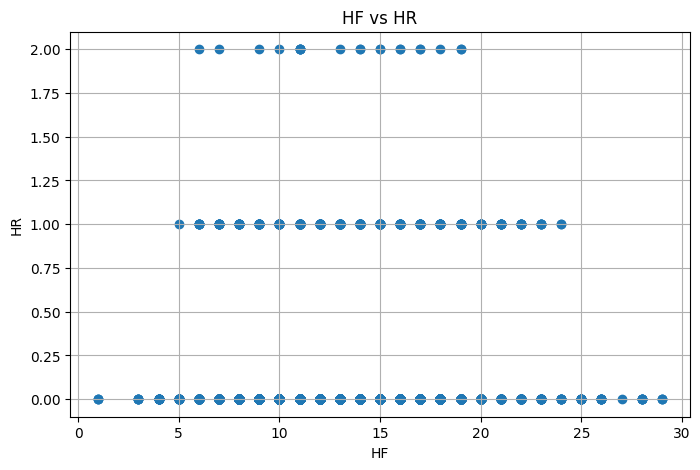

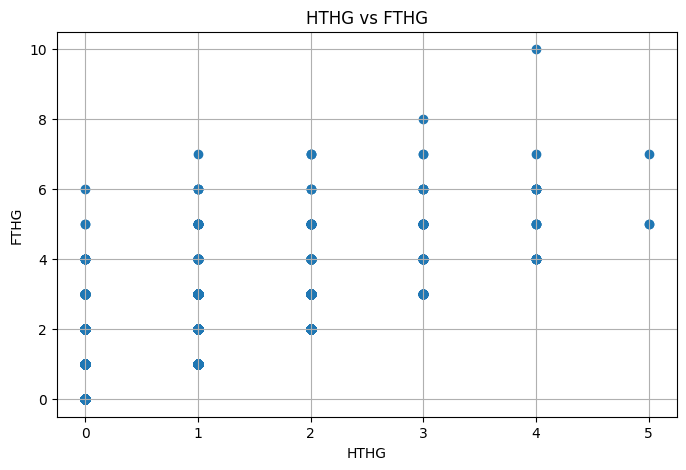

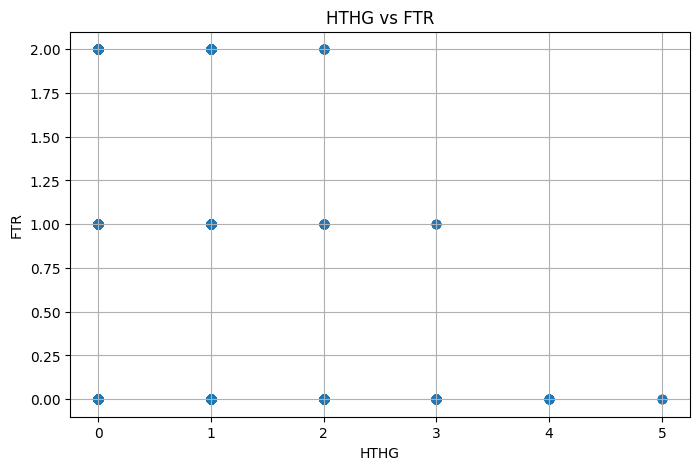

In [24]:
pairs_home = [
    ("HST", "FTHG"),
    ("HS", "HST"),
    ("HC", "FTHG"),
    ("HF", "HY"),
    ("HF", "HR"),
    ("HTHG","FTHG"),
    ("HTHG", "FTR")
]

for x, y in pairs_home:
    plt.figure(figsize=(8, 5))
    plt.scatter(df[x], df[y])
    plt.title(f"{x} vs {y}")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.grid(True)
    plt.show()


away scatter plots

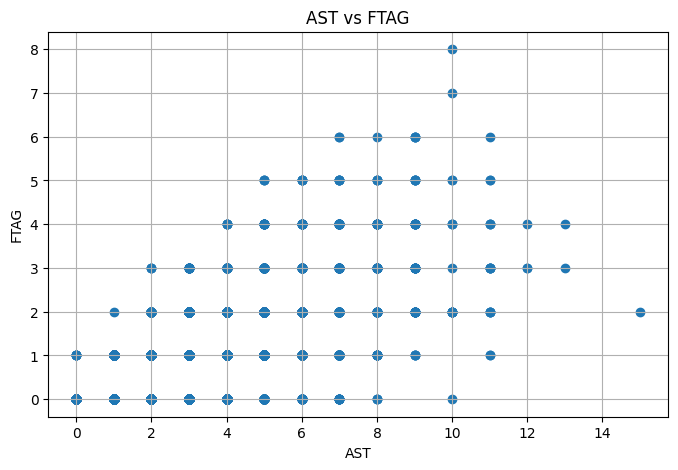

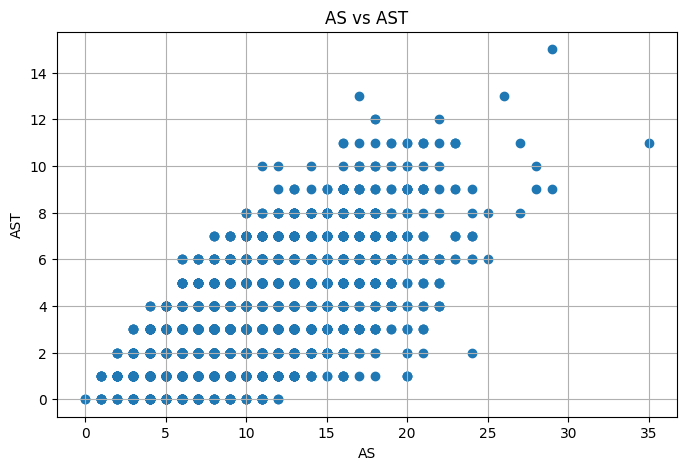

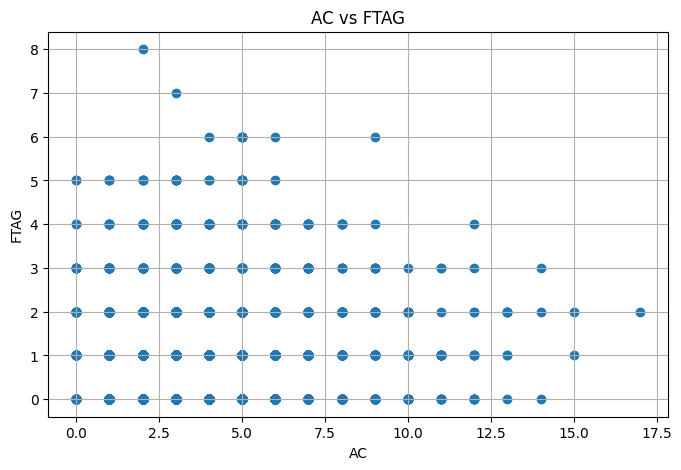

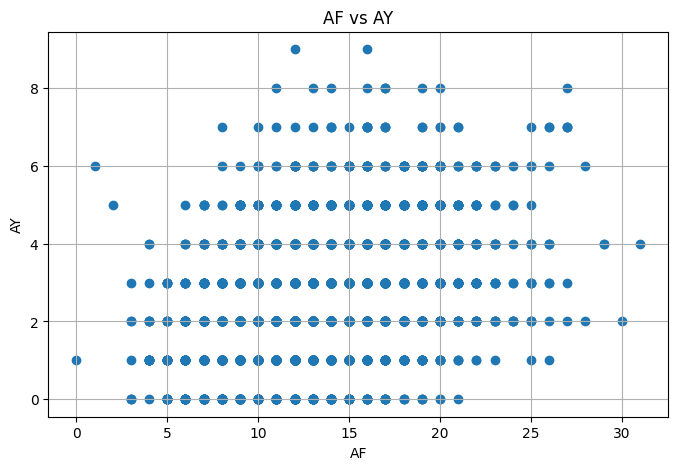

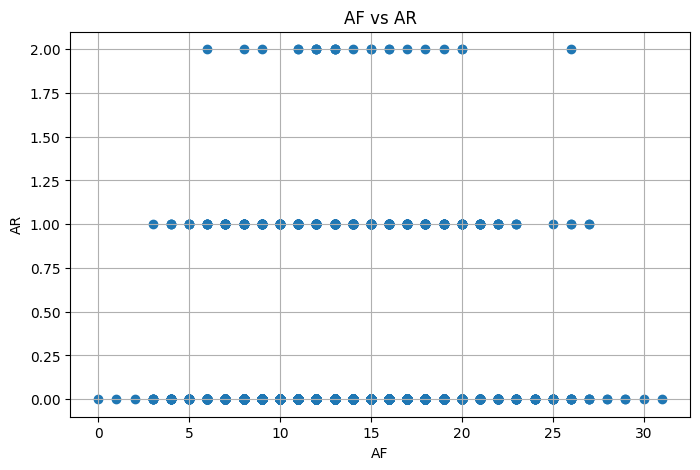

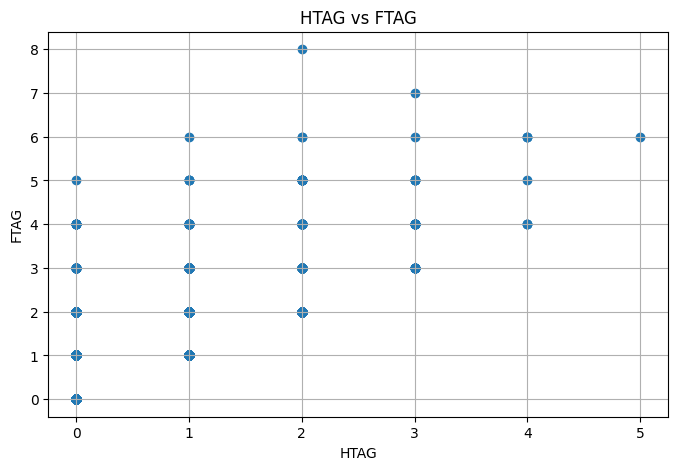

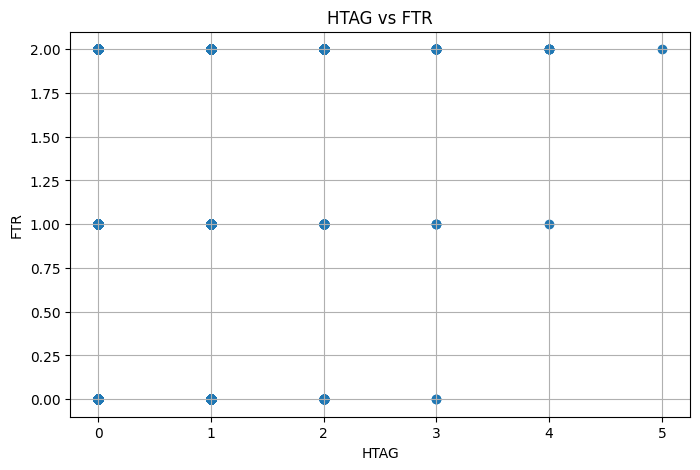

In [25]:
pairs_home = [
    ("AST", "FTAG"),
    ("AS", "AST"),
    ("AC", "FTAG"),
    ("AF", "AY"),
    ("AF", "AR"),
    ("HTAG","FTAG"),
    ("HTAG", "FTR")
]

for x, y in pairs_home:
    plt.figure(figsize=(8, 5))
    plt.scatter(df[x], df[y])
    plt.title(f"{x} vs {y}")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.grid(True)
    plt.show()


Multivariate Analysis

1 pairplots (multiple numerical features)

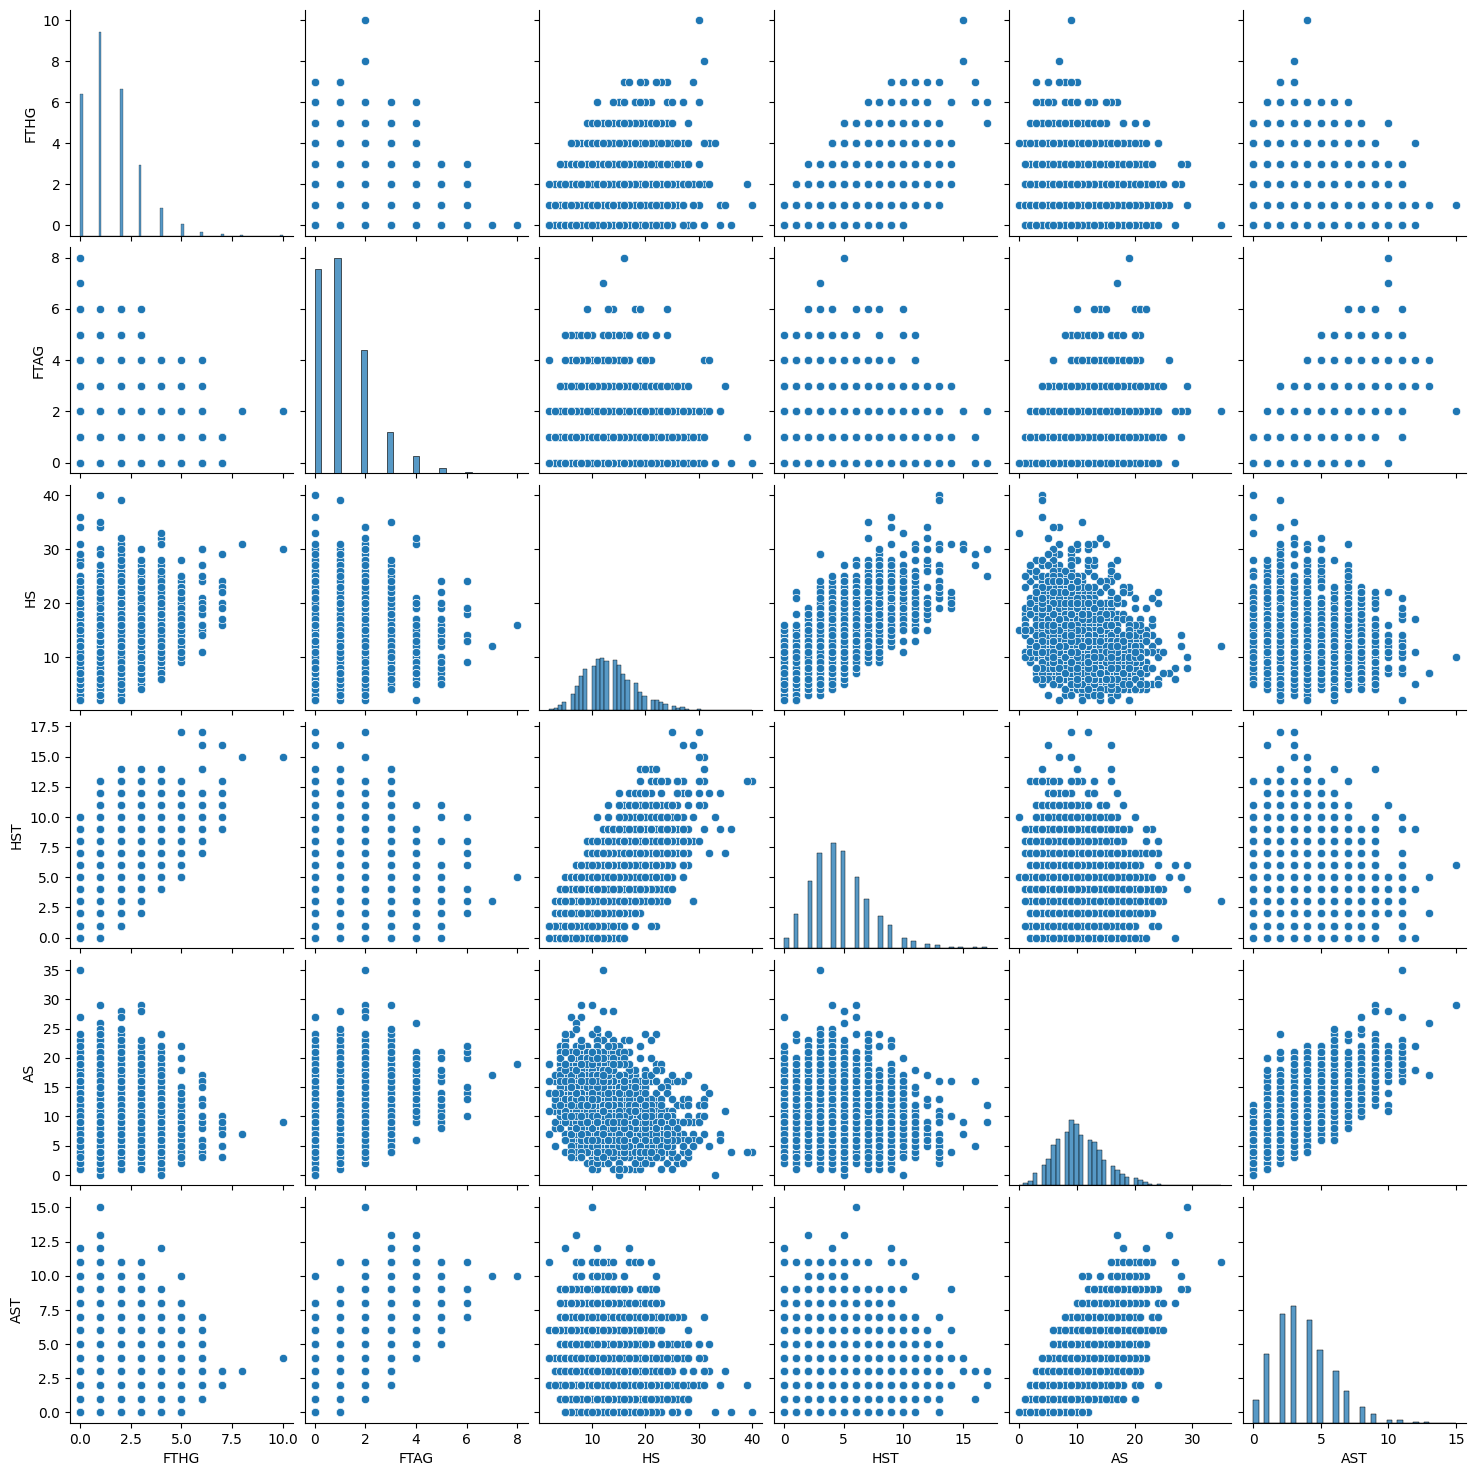

In [26]:
num_cols1 = ['FTHG', 'FTAG', 'HS', 'HST', 'AS', 'AST']

sns.pairplot(df[num_cols1])
plt.show()

2 3D Scatter Plot

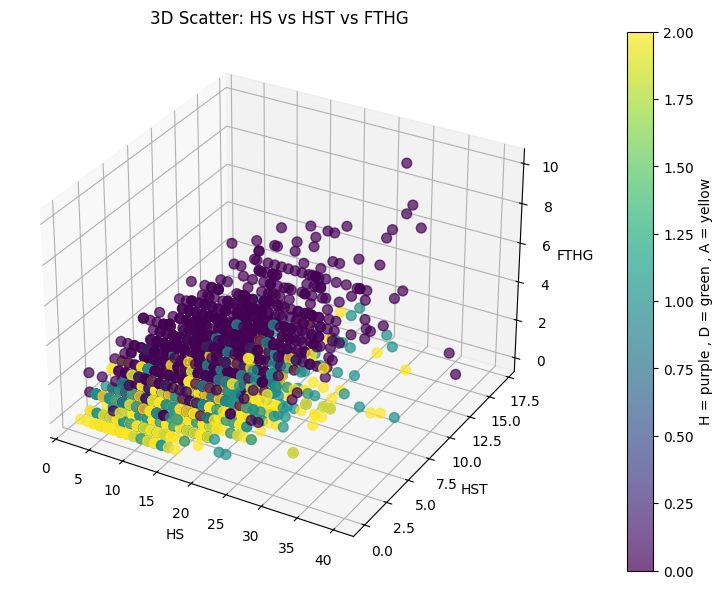

In [27]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
x = df['HS']
y = df['HST']
z = df['FTHG']
colors = df['FTR']
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(x, y, z, c=colors, cmap='viridis', marker='o', s=50, alpha=0.7)
ax.set_xlabel('HS')
ax.set_ylabel('HST')
ax.set_zlabel('FTHG')
ax.set_title('3D Scatter: HS vs HST vs FTHG')
cbar = plt.colorbar(scatter, pad=0.1)
cbar.set_label('H = purple , D = green , A = yellow')

plt.show()


3 Cluster Analysis (K-Means)

In [28]:
# from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[num_cols])
# kmeans = KMeans(n_clusters=3, random_state=42)
# clusters = kmeans.fit_predict(scaled_data)
# df['Cluster'] = clusters
# df['Cluster'].value_counts()




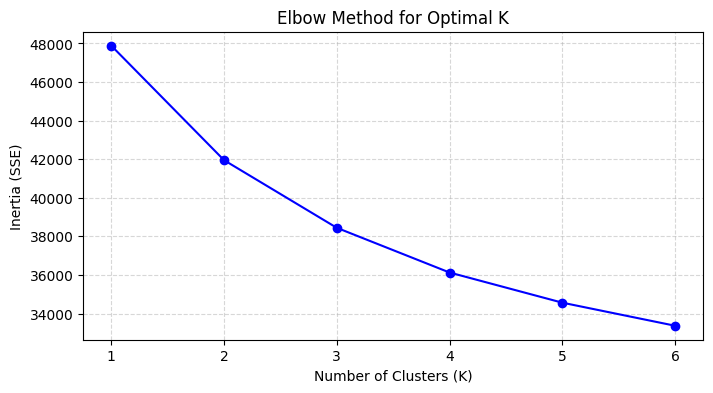

In [29]:
from sklearn.cluster import KMeans


RANDOM_STATE = 42

inertia_values = []
K_range = range(1, 7)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE)
    km.fit(scaled_data)
    inertia_values.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia_values, "bo-")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (SSE)")
plt.title("Elbow Method for Optimal K")
plt.xticks(K_range)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

4 PCA

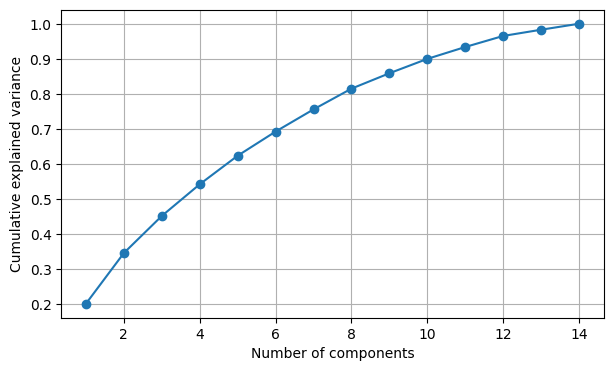

In [30]:
X = df[num_cols].copy()
X = X.dropna()
from sklearn.decomposition import PCA
pca = PCA()
X_pca = pca.fit_transform(scaled_data)
explained = pca.explained_variance_ratio_
plt.figure(figsize=(7,4))
plt.plot(range(1, len(explained)+1), explained.cumsum(), marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid(True)
plt.show()


In [31]:
print(num_cols)
print(type(num_cols[0]))
print(df['FTHG'].dtype)

['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']
<class 'str'>
int64


# **4 Outliers Analysis & Data Quality Checks**

1 Zscore / IQR Method

In [32]:
from scipy.stats import zscore
import numpy as np


num_data = df[num_cols]

# Z-score method calculates how far each value from the mean and std
z_scores = zscore(num_data, nan_policy='omit') # omit to igonre any missing values
outliers_z = np.abs(z_scores) > 3

df_z_clean = df[~outliers_z.any(axis=1)]

# IQR method
Q1 = num_data.quantile(0.25)
Q3 = num_data.quantile(0.75)
IQR = Q3 - Q1

outliers_iqr = (
    (num_data < (Q1 - 1.5 * IQR)) |
    (num_data > (Q3 + 1.5 * IQR))
)

df_iqr_clean = df[~outliers_iqr.any(axis=1)]

2. Visual Check After Cleaning

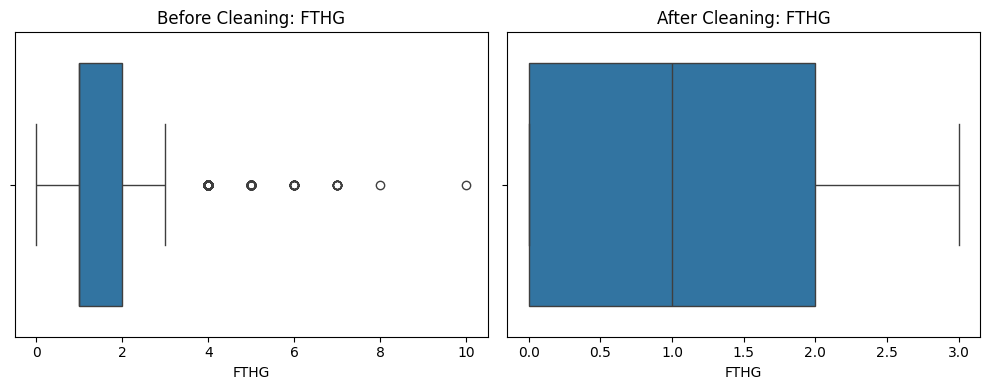

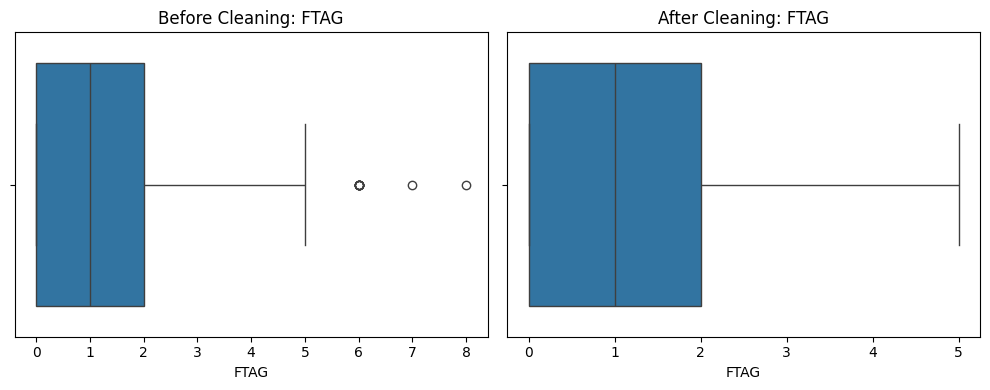

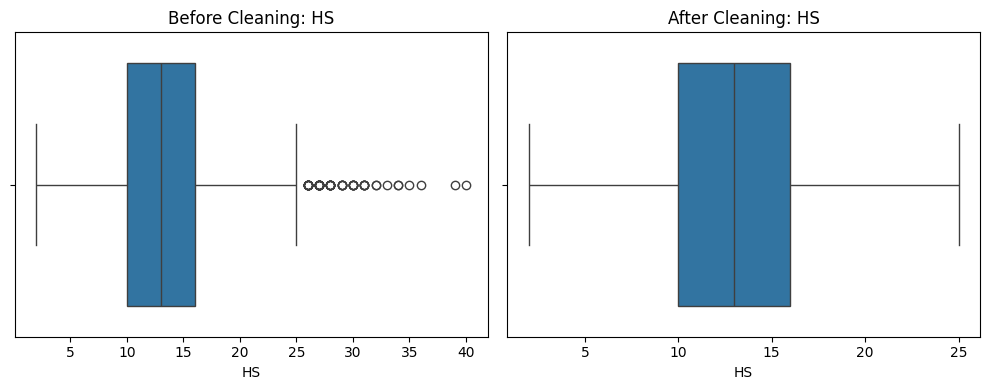

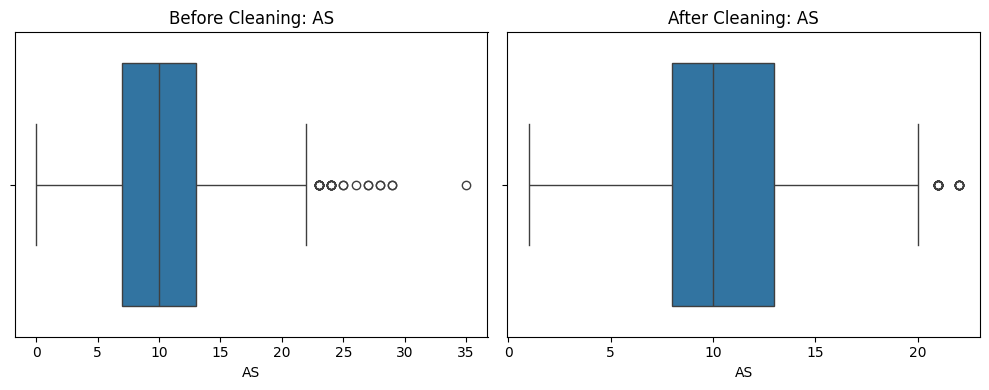

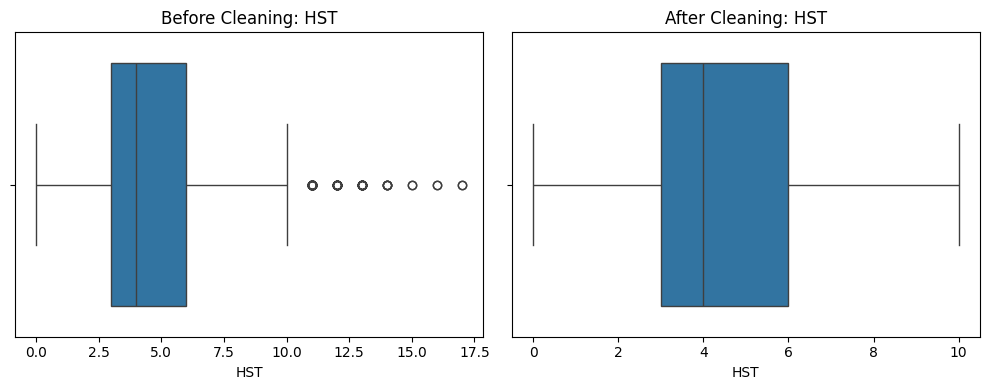

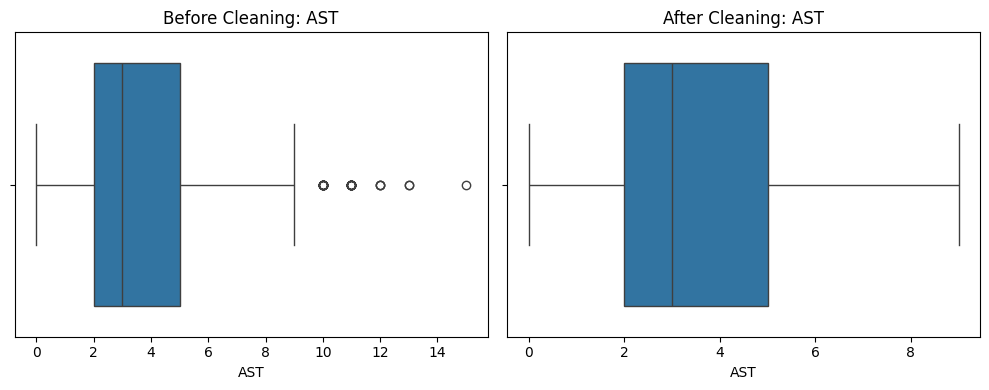

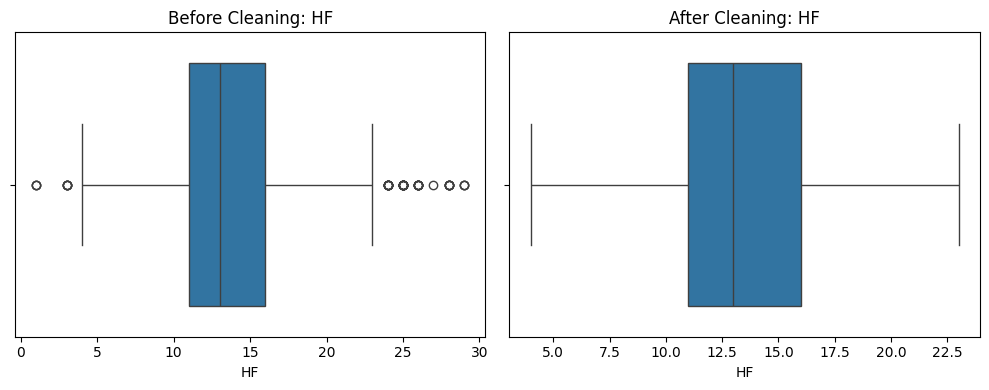

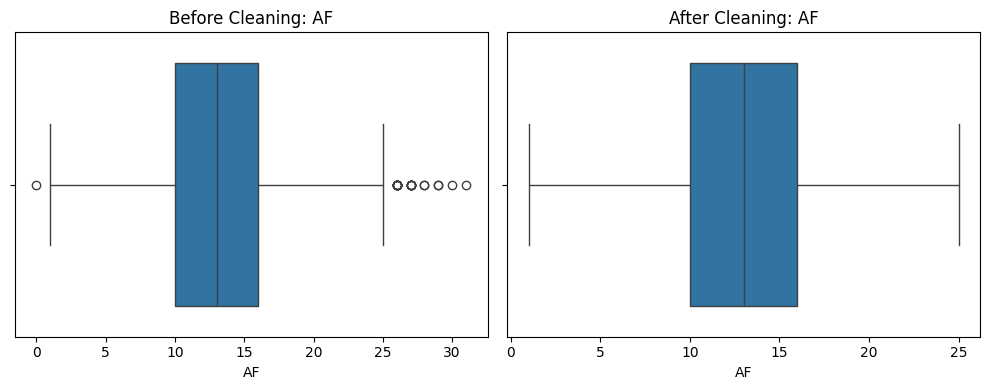

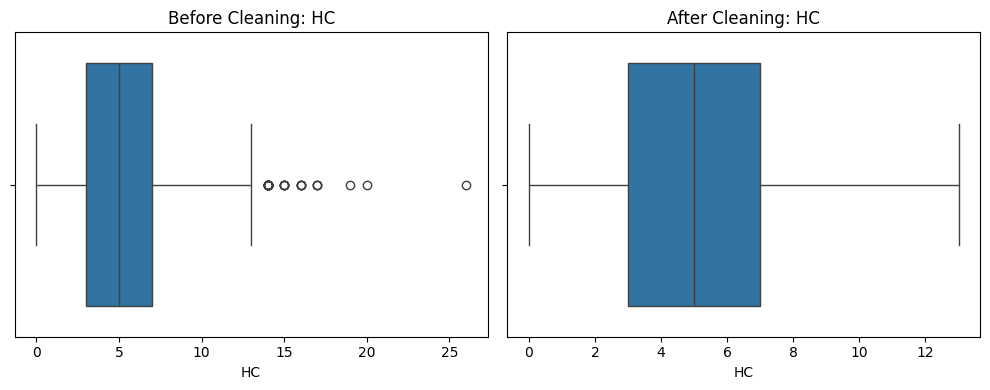

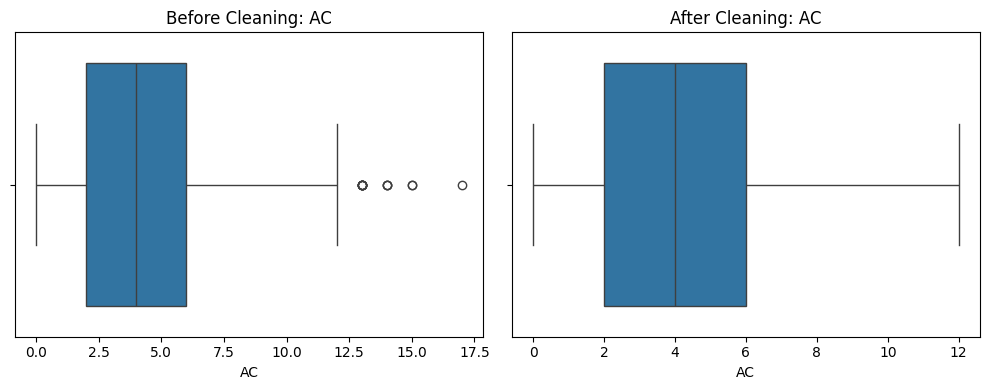

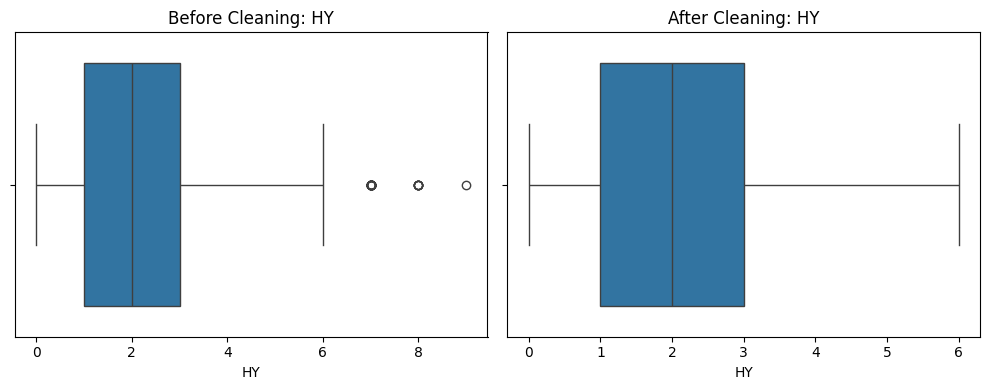

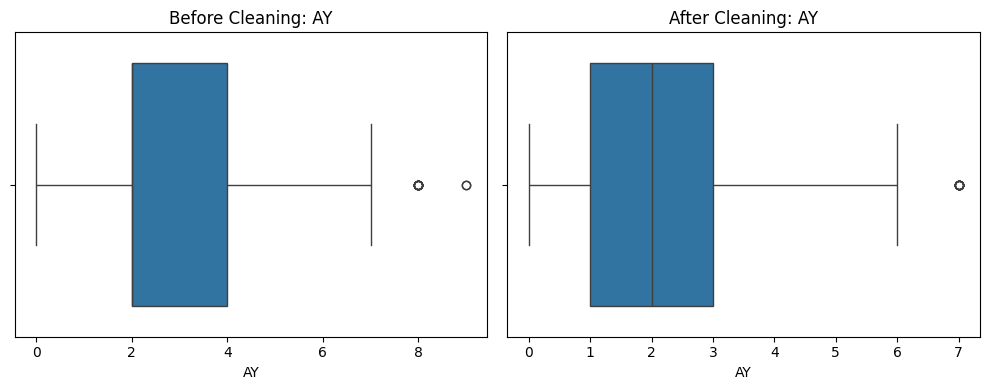

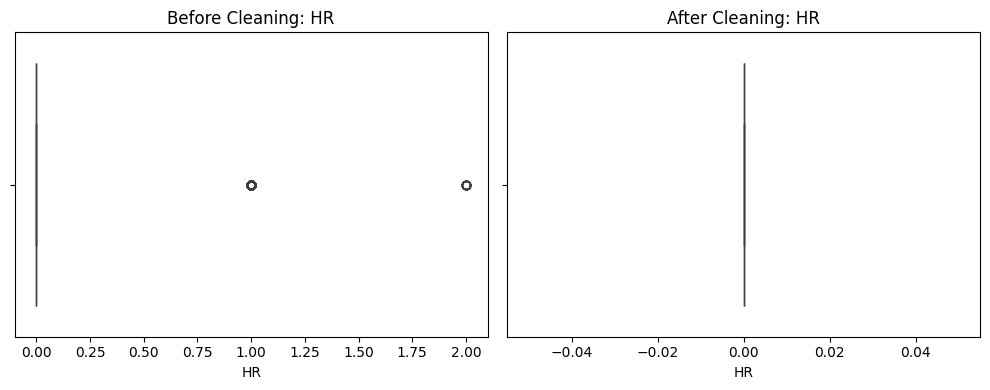

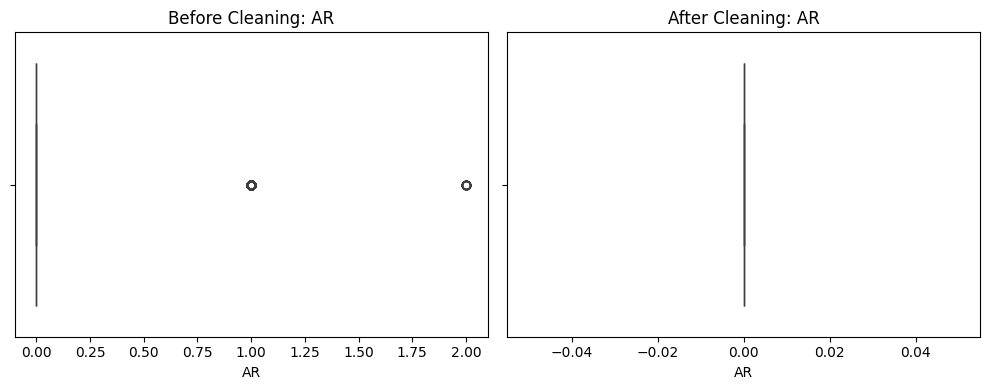

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting IQR
for col in num_cols:
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    sns.boxplot(x=df[col])
    plt.title(f"Before Cleaning: {col}")

    plt.subplot(1, 2, 2)
    sns.boxplot(x=df_iqr_clean[col])
    plt.title(f"After Cleaning: {col}")

    plt.tight_layout()
    plt.show()

3 Check Logical Validity

In [34]:
print("Negative Home Goals:", (df['FTHG'] < 0).sum())
print("Negative Away Goals:", (df['FTAG'] < 0).sum())
print("HST > HS:", (df['HST'] > df['HS']).sum())
print("AST > AS:", (df['AST'] > df['AS']).sum())
print("Same Team Playing Itself:", (df['HomeTeam'] == df['AwayTeam']).sum())

invalid_results = df[
    ((df['FTHG'] > df['FTAG']) & (df['FTR'] != 0)) |
    ((df['FTHG'] < df['FTAG']) & (df['FTR'] != 2)) |
    ((df['FTHG'] == df['FTAG']) & (df['FTR'] != 1))
]

print("Invalid Match Results:", len(invalid_results))


Negative Home Goals: 0
Negative Away Goals: 0
HST > HS: 0
AST > AS: 0
Same Team Playing Itself: 0
Invalid Match Results: 0


4 Identify rare categories

In [35]:
threshold = 0.01 * len(df)

for col in cat_cols:
    counts = df[col].value_counts()
    rare = counts[counts < threshold]

    print(f"\nRare categories in {col}:")
    print(rare if len(rare) > 0 else "None")


Rare categories in HomeTeam:
HomeTeam
14    19
Name: count, dtype: int64

Rare categories in AwayTeam:
AwayTeam
14    19
Name: count, dtype: int64

Rare categories in HTR:
None

Rare categories in FTR:
None


# **5 Insights & Reporting**

1 feature importance

   Feature  Importance
4      HST    0.572094
2       HS    0.066042
6       HF    0.042381
7       AF    0.042278
3       AS    0.040698
0     FTHG    0.038842
8       HC    0.037585
9       AC    0.033563
5      AST    0.032869
11      AY    0.030506
10      HY    0.028002
1     FTAG    0.021999
13      AR    0.007394
12      HR    0.005747


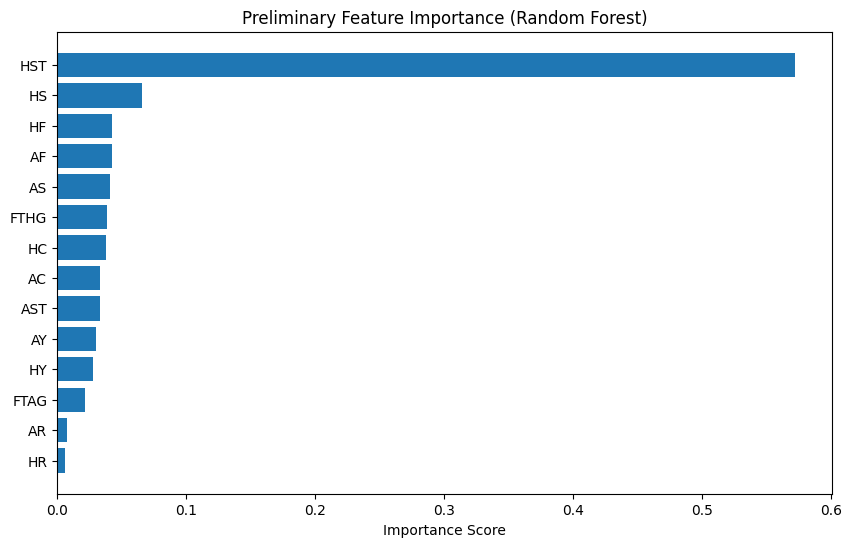

In [36]:
drop_target_FTR = df.drop(columns=['FTR'])
target_FTR = df['FTR']
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200, # build 200 trees
    random_state=42,
    n_jobs=-1 # use all cpu cores
)

rf.fit(X, y)


importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importance_df)



plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)
plt.gca().invert_yaxis()
plt.title("Preliminary Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.show()



2 Automated EDA report

In [37]:
!pip install ydata-profiling


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.3 MB/s eta 0:00:00


In [38]:
from ydata_profiling import ProfileReport

# Generate report
profile = ProfileReport(df, title="Football Dataset EDA", explorative=True)

# Save it as HTML and display
profile.to_file("eda_report.html")


/tmp/ipykernel_1155/810221907.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:00<00:00, 24.50it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [39]:

df_model = df.copy()

y = df_model["FTR"]

cols_to_drop = ["FTHG", "FTAG", "HTR", "HTHG", "HTAG", "FTR"]

X = df_model.drop(columns=cols_to_drop)

print("X shape:", X.shape)
print("y distribution:\n", y.value_counts())


X shape: (3420, 14)
y distribution:
 FTR
0    1568
2     966
1     886
Name: count, dtype: int64


xgboost using boosting
Build one tree.
Check its mistakes.
Build the next tree to correct those mistakes.
Repeat.

In [40]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
param_grid = {
    'n_estimators': [200, 400],#number of trees
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],# each tree sees only 70% or 80% or 100% of matches raandomly to reduce overfitting
    'colsample_bytree': [0.7, 0.8, 1.0]#same but with the features
}

model = XGBClassifier(
    objective="multi:softmax", # used for multiclass classification
    num_class=3, # number of classes which are H , A , D
    eval_metric="mlogloss", # how confident the model of its prediction if lower then better
    random_state=42
)

grid_search = GridSearchCV(
    estimator= model,
    param_grid=param_grid,
    cv=3, # split training data into 3 parts train on 2 and validate on 1 then repeat 3 times
    scoring='accuracy',
    verbose=1, #print status for eatch hyperparameter combination
    n_jobs=-1 #use all cpu cores
)

grid_search.fit(X_train, y_train)


best_model = grid_search.best_estimator_


y_pred = best_model.predict(X_test)

print("Best hyperparameters:", grid_search.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 162 candidates, totalling 486 fits
Best hyperparameters: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 400, 'subsample': 0.8}
Accuracy: 0.6125730994152047
              precision    recall  f1-score   support

           0       0.67      0.84      0.74       314
           1       0.42      0.27      0.33       177
           2       0.62      0.55      0.58       193

    accuracy                           0.61       684
   macro avg       0.57      0.56      0.55       684
weighted avg       0.59      0.61      0.59       684



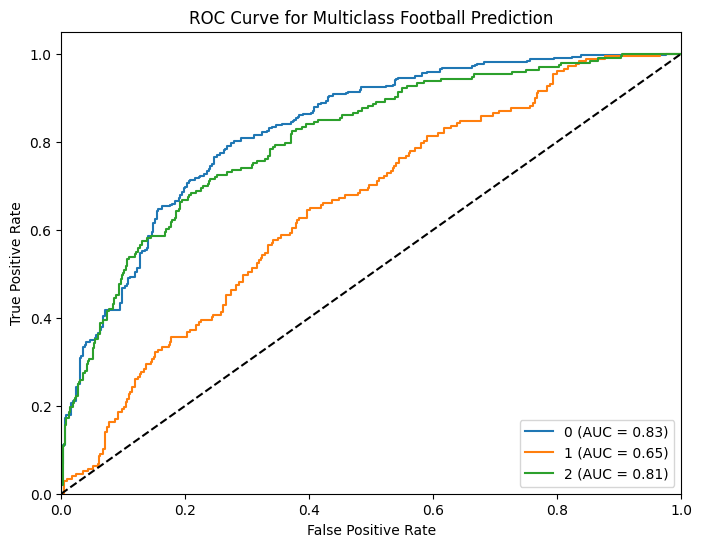

In [41]:
y_proba = best_model.predict_proba(X_test)

from sklearn.preprocessing import label_binarize # to make it on vs the rest beacuse roc works on binary but we have 3 classes


classes = best_model.classes_  # to get the class order which is H,D,A
y_test_bin = label_binarize(y_test, classes=classes) #make the H = 1,0,0 , Draw = 0,1,0 and away = 0,0,1

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

for i, cls in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], y_proba[:, i]) # y_test_bin[:, i] is true labels for this class  , y_proba[:, i] = Predicted probability for this class
    roc_auc = auc(fpr, tpr) #calculate AUC
    plt.plot(fpr, tpr, label=f'{cls} (AUC = {roc_auc:.2f})') #ploat FPR vs TPR and AUC score

plt.plot([0, 1], [0, 1], 'k--')  # diagonal line for random classifier
plt.xlim([0.0, 1.0]) # axis limits
plt.ylim([0.0, 1.05]) #axis limits
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multiclass Football Prediction')
plt.legend(loc='lower right')
plt.show()



In [42]:
# to see the mlogloss
y_proba = best_model.predict_proba(X_test)
y_pred = best_model.predict(X_test)
confidence = np.max(y_proba, axis=1)
for i, (pred, conf, actual) in enumerate(zip(y_pred, confidence, y_test)):
    print(f"Match {i+1}: Predicted = {pred} ({conf:.2f}), Actual = {actual}")






Match 1: Predicted = 0 (0.93), Actual = 0
Match 2: Predicted = 0 (0.60), Actual = 1
Match 3: Predicted = 0 (0.58), Actual = 1
Match 4: Predicted = 0 (0.90), Actual = 0
Match 5: Predicted = 0 (0.71), Actual = 0
Match 6: Predicted = 0 (0.48), Actual = 0
Match 7: Predicted = 2 (0.70), Actual = 2
Match 8: Predicted = 2 (0.61), Actual = 2
Match 9: Predicted = 2 (0.75), Actual = 0
Match 10: Predicted = 0 (0.85), Actual = 0
Match 11: Predicted = 0 (0.50), Actual = 0
Match 12: Predicted = 0 (0.48), Actual = 1
Match 13: Predicted = 1 (0.51), Actual = 1
Match 14: Predicted = 2 (0.74), Actual = 2
Match 15: Predicted = 1 (0.69), Actual = 2
Match 16: Predicted = 0 (0.42), Actual = 1
Match 17: Predicted = 0 (0.63), Actual = 0
Match 18: Predicted = 0 (0.50), Actual = 0
Match 19: Predicted = 2 (0.69), Actual = 1
Match 20: Predicted = 2 (0.44), Actual = 1
Match 21: Predicted = 2 (0.71), Actual = 1
Match 22: Predicted = 1 (0.61), Actual = 2
Match 23: Predicted = 2 (0.68), Actual = 2
Match 24: Predicted 

In [43]:

import joblib
from google.colab import files
import json


joblib.dump(best_model, "xgb_model.pkl")
print("Saved xgb_model.pkl")


try:
    joblib.dump(le_team, "le_team.pkl")
    print("Saved le_team.pkl")
except NameError:
    print("le_team not found in namespace — skip saving encoder.")


try:
    feature_names = list(X.columns)
    with open("feature_names.json", "w") as f:
        json.dump(feature_names, f)
    print("Saved feature_names.json with", len(feature_names), "features.")
except Exception as e:
    print("Could not save feature names automatically:", e)
    print("If X isn't a DataFrame, create feature_names = [...your feature list...] and save it manually.")


Saved xgb_model.pkl
Saved le_team.pkl
Saved feature_names.json with 14 features.


In [44]:
from google.colab import files
files.download("xgb_model.pkl")
files.download("le_team.pkl")
files.download("feature_names.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>